# Porter: Delivery Time Estimation using Neural Networks

**Section 4 of 5 (10 marks): Model Training with Random Forest**

| Section | Topic | Marks | File |
|:--:|:--|:--:|:--|
| 1 | Problem Statement, Data Import and Data Structure Analysis | 10 | [open](section_1_problem_and_data.ipynb) |
| 2 | Data Preprocessing and Feature Engineering | 30 | [open](section_2_preprocessing.ipynb) |
| 3 | Data Visualization, Outlier Detection and Cleaning | 20 | [open](section_3_visualization_outliers.ipynb) |
| 4 | Model Training with Random Forest | 10 | **you are here** |
| 5 | Regression with Neural Networks | 30 | [open](section_5_neural_network.ipynb) |

**Note.** This notebook continues from [section_3_visualization_outliers.ipynb](section_3_visualization_outliers.ipynb): it uses the data, variables and functions created in the earlier sections, and the outputs below were saved from one full run of the whole case study. To run the code again, run the cells in order from Section 1 (use `../solution.ipynb` to do this in one go).

<a id="sec4"></a>

# Section 4: Model Training with Random Forest (10 points)

### Objective and Tasks of this Section

**Stage 4 of 5 · 4 Tasks: Baseline Model with Random Forest**

**Objective:** You will split the cleaned data into train and test sets, train a random forest baseline, and evaluate it thoroughly so it can act as a benchmark for the neural network.

| Task | What to do | Hint |
|:--|:--|:--|
| **Task 4.1** | Split the cleaned, encoded data into training and test sets in a reproducible way. | Think about which train_test_split parameter controls the proportion held out for testing, and which one makes the split reproducible across runs. |
| **Task 4.2** | Train a random forest regression model as your baseline. | Think about which scikit-learn class implements an ensemble of decision trees for a regression target. |
| **Task 4.3** | Evaluate the random forest on the test set using multiple error metrics, and identify which features matter most. | Think about why reporting more than one error metric (magnitude in the same unit as the target, plus a normalized/percentage view) gives a fuller picture than a single number. |
| **Task 4.4** | Name other classical machine learning methods (besides random forest) that could be used for this regression problem. | Think about other regression algorithms you know that don't rely on neural networks — both linear and tree/ensemble-based. |

**Evaluation criteria of this section (10 points):**

| Criterion | Done in |
|:--|:--|
| Data splitting | 4.1 |
| Random forest regression | 4.2, 4.3 |

Each task below is marked in its heading, for example `(Task 4.1)`.

---


Before building a neural network we need a baseline: a strong, simple model whose numbers the neural network must beat. As in the brief, we split the data into train and test sets, train a Random Forest, and check its MSE, RMSE and MAE.

**Flow of this section:**

```
Encode & split --> Random Forest --> Metrics --> Other classical methods
```

## 4.1 Preparing the Features and Splitting the Data (Task 4.1)

`market_id` and `order_protocol` are labels, so we turn them into one-hot columns with `pd.get_dummies(..., dtype=float)`. `store_category_code` keeps its integer codes. Then `X` holds the inputs and `y` the target.

In [58]:
X = pd.get_dummies(df.drop(columns=["time_taken_mins"]), columns=["market_id", "order_protocol"], dtype=float)
y = df["time_taken_mins"]

print(X.shape, y.shape)
X.head()

(172914, 24) (172914,)


,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,hour,day_of_week,...,market_id_4,market_id_5,market_id_6,order_protocol_1,order_protocol_2,order_protocol_3,order_protocol_4,order_protocol_5,order_protocol_6,order_protocol_7
0,4,3441,4,557,1239,33.0,14.0,21.0,22,4,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,1900,1,1400,1400,1.0,2.0,2.0,21,1,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,4,4771,3,820,1604,8.0,6.0,18.0,0,0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,1,1525,1,1525,1525,5.0,6.0,8.0,3,3,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2,3620,2,1425,2195,5.0,5.0,7.0,2,1,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


`train_test_split` keeps 20% of the rows for testing. `random_state=42` makes the split reproducible, so every run gives the same train and test sets. We do not use `stratify`, because the target is a continuous number.

In [59]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train:", X_train.shape, y_train.shape)
print("Test :", X_test.shape, y_test.shape)

Train: (138331, 24) (138331,)
Test : (34583, 24) (34583,)


The test set must look like the training set. Let's check the delivery time in both.

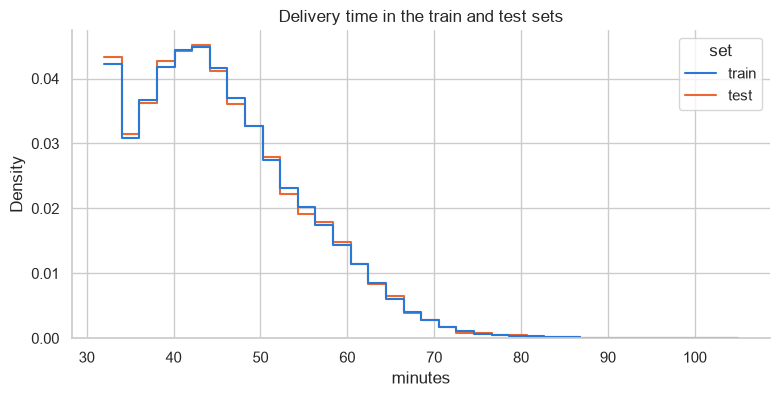

In [60]:
split_target = pd.concat([
    pd.DataFrame({"minutes": y_train, "set": "train"}),
    pd.DataFrame({"minutes": y_test, "set": "test"}),
])

plt.figure(figsize=(9, 4))
sns.histplot(data=split_target, x="minutes", hue="set", binwidth=2, stat="density", common_norm=False,
             element="step", fill=False, palette=[BLUE, ORANGE])
plt.title("Delivery time in the train and test sets")
plt.show()

From the output above, the split gives 138,331 training rows and 34,583 test rows, each with 24 feature columns. In the histogram the delivery-time curves of the two sets lie almost on top of each other, so the test set is a fair sample of the same kind of orders.

## 4.2 Random Forest Regression (Task 4.2)

`RandomForestRegressor` builds many decision trees on random parts of the data and averages their predictions. We use 100 trees, `n_jobs=-1` to use all processor cores, and a fixed `random_state`.

**Note:** A Random Forest splits on thresholds, so it does not need scaled features (see Section 5.1).

In [61]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

## 4.3 Evaluate the Random Forest and Find the Important Features (Task 4.3)

We report MSE, RMSE and MAE, as in the brief. We also report two normalised views: R² (the share of the variation in delivery time that the model explains, which tells us how accurate the model is) and MAPE (the average error as a percentage of the true delivery time). MAE is the average miss in minutes, RMSE is also in minutes but punishes big misses more, and MSE is the quantity a neural network minimises. The training scores next to the test scores show whether the forest has memorised the training data.

In [62]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def regression_report(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    mape = float(np.mean(np.abs((np.asarray(y_true) - y_pred) / np.asarray(y_true))) * 100)
    return dict(MSE=mse, RMSE=mse ** 0.5, MAE=mean_absolute_error(y_true, y_pred), R2=r2_score(y_true, y_pred), MAPE_percent=mape)

rf_train_pred = rf.predict(X_train)
rf_test_pred = rf.predict(X_test)

rf_train_res = regression_report(y_train, rf_train_pred)
rf_test_res = regression_report(y_test, rf_test_pred)

pd.DataFrame({"Random Forest (train)": rf_train_res, "Random Forest (test)": rf_test_res}).round(3)

,Random Forest (train),Random Forest (test)
MSE,3.109,22.015
RMSE,1.763,4.692
MAE,1.368,3.678
R2,0.963,0.744
MAPE_percent,3.017,8.135


Two charts show where the Random Forest is right and wrong. On the left, each dot is an order: a perfect model would put every dot on the dashed diagonal. On the right is the distribution of the errors (actual minus predicted).

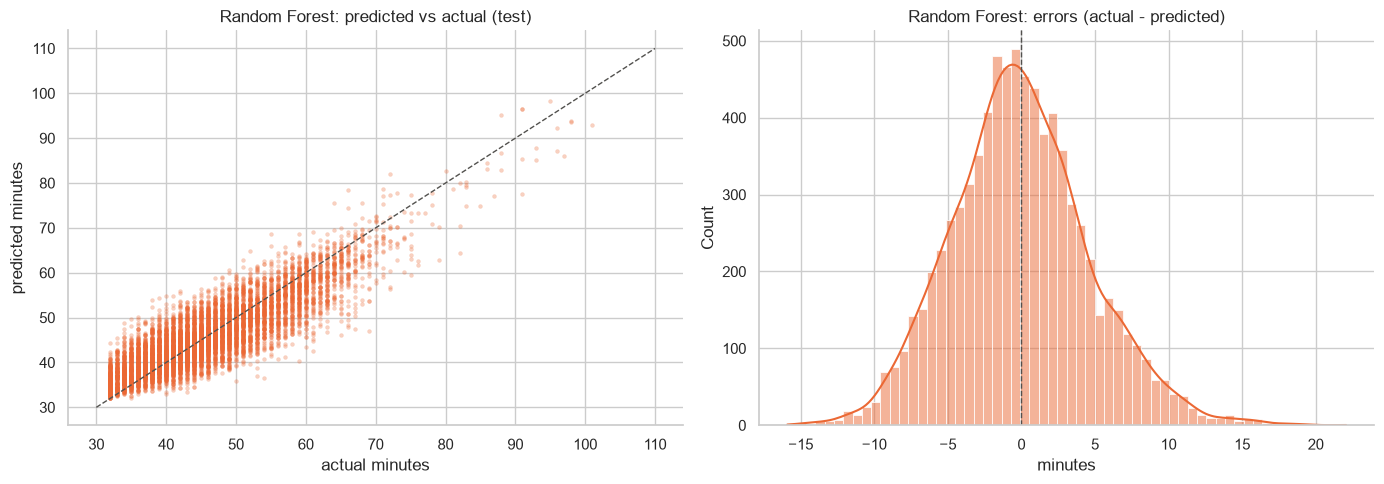

In [63]:
test_sample = pd.DataFrame({"actual": y_test.values, "predicted": rf_test_pred}).sample(8000, random_state=42)
test_sample["error"] = test_sample["actual"] - test_sample["predicted"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=test_sample, x="actual", y="predicted", s=8, alpha=0.3, color=ORANGE, edgecolor=None, ax=axes[0])
axes[0].plot([30, 110], [30, 110], color="#52514e", linestyle="--", linewidth=1)
axes[0].set_title("Random Forest: predicted vs actual (test)")
axes[0].set_xlabel("actual minutes")
axes[0].set_ylabel("predicted minutes")

sns.histplot(test_sample["error"], bins=60, kde=True, color=ORANGE, ax=axes[1])
axes[1].axvline(0, color="#52514e", linestyle="--", linewidth=1)
axes[1].set_title("Random Forest: errors (actual - predicted)")
axes[1].set_xlabel("minutes")
plt.tight_layout()
plt.show()

From the output above, on the test set the forest is off by 3.68 minutes on average (MAE), its RMSE is 4.69 minutes, its R² is 0.744, and its average error is 8.1% of the true delivery time (MAPE). On the training set the same forest has an RMSE of only 1.76 and an R² of 0.963, so it has partly memorised the training rows. The gap between 1.76 and 4.69 is the price of that overfitting, and the test numbers are the ones to trust.

For scale, a model that always predicts the average delivery time would be off by about 9 minutes (the standard deviation of the target), so the forest removes roughly half of that error. In the chart on the left the forest follows the diagonal, but for slow deliveries (above about 70 minutes) it tends to predict too low.

Which features does the forest rely on most? `feature_importances_` shows how much each feature reduced the error across all the trees.

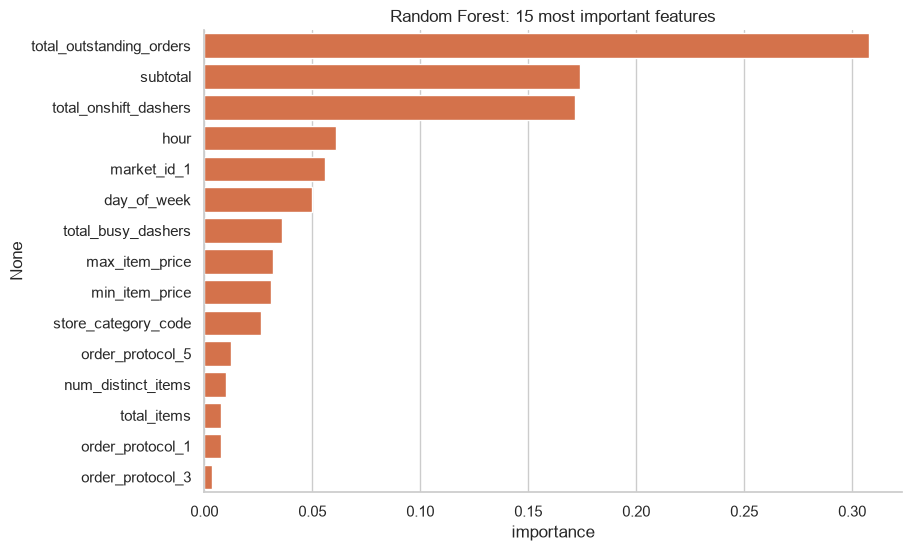

In [64]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
sns.barplot(x=importance.values, y=importance.index, color=ORANGE)
plt.title("Random Forest: 15 most important features")
plt.xlabel("importance")
plt.show()

From the chart, the forest relies most on `total_outstanding_orders` (about 0.31), then on `subtotal` and `total_onshift_dashers` (about 0.17 each), followed by `hour`, `market_id_1` and `day_of_week`. The partner columns are strongly correlated with each other (Section 3.1), so the forest splits their importance between them: read the ranking as groups of features, not as exact scores.

## 4.4 Other Classical Methods for Regression (Task 4.4, Brief Question 6)

> **Brief Question 6:** *What classical machine learning methods can we use other than random forest for regression?*


Besides Random Forest, these classical machine learning methods can predict a number:

| Method | Idea |
|:--|:--|
| Linear Regression (and Ridge, Lasso) | A weighted sum of the features, with optional penalties on large weights |
| Decision Tree Regressor | One tree of yes/no splits |
| Gradient Boosting (XGBoost, LightGBM, `GradientBoostingRegressor`) | Many small trees, each correcting the errors of the previous ones |
| K-Nearest Neighbours Regressor | The average of the most similar training orders |
| Support Vector Regression | A kernel method that fits a tube around the data |

### A Quick Test of Some of Them

The brief only asks us to name the methods. Since it takes a minute, we also train three of them on the same training rows and score them on the same test rows, so that the Random Forest result can be put in perspective. These scores are not used to choose anything.

In [65]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

classical = {"Linear Regression": LinearRegression(),
             "Decision Tree (at least 20 rows per leaf)": DecisionTreeRegressor(min_samples_leaf=20, random_state=42),
             "Gradient Boosting (HistGradientBoosting)": HistGradientBoostingRegressor(random_state=42)}

classical_rows = {}
for name, model in classical.items():
    model.fit(X_train, y_train)
    classical_rows[name] = regression_report(y_test, model.predict(X_test))
classical_rows["Random Forest (Section 4.3)"] = rf_test_res

pd.DataFrame(classical_rows).T[["RMSE", "MAE", "R2", "MAPE_percent"]].round(3)

,RMSE,MAE,R2,MAPE_percent
Linear Regression,5.134,4.038,0.693,9.005
Decision Tree (at least 20 rows per leaf),5.195,4.032,0.686,8.883
Gradient Boosting (HistGradientBoosting),4.573,3.602,0.756,7.952
Random Forest (Section 4.3),4.692,3.678,0.744,8.135


From the table, the ensembles are clearly better than the two simple models: Linear Regression (RMSE 5.13) and the single Decision Tree (5.20) are about 0.4 to 0.5 minutes worse than the Random Forest (4.69), and Gradient Boosting is the best of the four (4.57, R² 0.756). So the link between the features and delivery time is not a straight line, and it needs a flexible model. These are test scores for models with default settings, shown for perspective. Section 5.5 compares the neural network (RMSE 4.44) with all of them.

## Section 4 Summary: Objective and How It Was Addressed

**Motto of this section:** *Set a baseline that is strong and honest, so that the neural network has something real to beat.*

| Task | Where it is addressed | Result |
|:--|:--|:--|
| **Task 4.1:** reproducible split | **4.1**: `pd.get_dummies` for `market_id` and `order_protocol`, `train_test_split(test_size=0.2, random_state=42)` | 138,331 train rows, 34,583 test rows, 24 features |
| **Task 4.2:** Random Forest | **4.2**: `RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)` | Trained on the training rows only |
| **Task 4.3:** metrics and important features | **4.3**: MSE, RMSE, MAE, R² and MAPE on train and test, charts, `feature_importances_` | Test RMSE 4.69, MAE 3.68, R² 0.744, MAPE 8.1%; most important: orders waiting, subtotal, partners on shift |
| **Task 4.4 and Question 6:** other classical methods | **4.4**: table of five methods, and a quick test of three | Linear 5.13, Decision Tree 5.20, Gradient Boosting 4.57 (test RMSE) |

**Baseline to beat:** test RMSE **4.69** minutes (train RMSE 1.76, so the forest overfits).